## Number of BHs versus host stellar masses

In [307]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import h5py

# The editable install means we can import this anywhere, no sys.path hacks needed.
import cosmo_sim_tools as cosmosim

# NOTE: importing the top-level package does NOT pull in the subpackages,
# so we import the helpers explicitly:
from cosmo_sim_tools.arepo_tools import arepo_package
from cosmo_sim_tools import illustris as il
from cosmo_sim_tools import brahma

# Shared figure styling (fonts, ticks, legend) lives in py_files/plot_style.py
sys.path.append('../../py_files/')
import plot_style as ps
#ps.set_style('paper', font_scale=1.15)

In [308]:
DATA_DIR = Path('/orange/lblecha/pranavsatheesh/wandering_bhs/Data')
FIGURE_DIR = Path('../../figures')

# catalogue name -> panel title
SEED_MODELS = {'SM5_DFD_3_TNG': 'SM5',
               'SM5_LW10_DFD_3_TNG': 'SM5_LW10',
               'SM5_LW10_LOWSPIN_RICH_DFD_3_TNG': 'SM5_LW10_LOWSPIN_RICH'}
REDSHIFTS = [5, 4, 3, 2, 0]

MIN_STAR_PARTICLES = 50   # about 1.1e7 Msun of stars
MIN_DM_PARTICLES = 50     # about 7.8e7 Msun of dark matter

LOG_MSTAR_BINS = np.arange(5.0, 12, 0.25)
MIN_HOSTS_PER_BIN = 10


def load_hosts(sim_name):
    """Snapshot, stellar mass and BH count of every BH-hosting subhalo in the catalogue."""
    catalogue = DATA_DIR / f'wandering_bh_{sim_name}.hdf5'
    with h5py.File(catalogue, 'r') as f:
        return dict(snap=f['subhalo/snap'][:],
                    stellar_mass=f['subhalo/stellar_mass_msun'][:],
                    bh_count=f['subhalo/bh_count'][:],
                    index=f['subhalo/index'][:],
                    snapshots=f['snapshot/snap'][:],
                    redshifts=f['snapshot/redshift'][:],
                    sim_file=f.attrs['sim_path'] + f.attrs['sim_name'])


def binned_percentiles(log_mstar, n_bh, bins=LOG_MSTAR_BINS, min_hosts=MIN_HOSTS_PER_BIN):
    """Median and 5th-95th percentile of N_BH in each stellar-mass bin holding enough hosts."""
    which_bin = np.digitize(log_mstar, bins) - 1
    centres, p5, p50, p95 = [], [], [], []
    for b in range(len(bins) - 1):
        in_bin = n_bh[which_bin == b]
        if len(in_bin) < min_hosts:
            continue
        centres.append(0.5 * (bins[b] + bins[b + 1]))
        lo, med, hi = np.percentile(in_bin, [5, 50, 95])
        p5.append(lo)
        p50.append(med)
        p95.append(hi)
    return np.array(centres), np.array(p5), np.array(p50), np.array(p95)

Median $N_{\rm BH}$ (line) and 5th–95th percentile (band) of BH-hosting galaxies, in 0.25 dex stellar-mass bins holding at least 5 hosts.

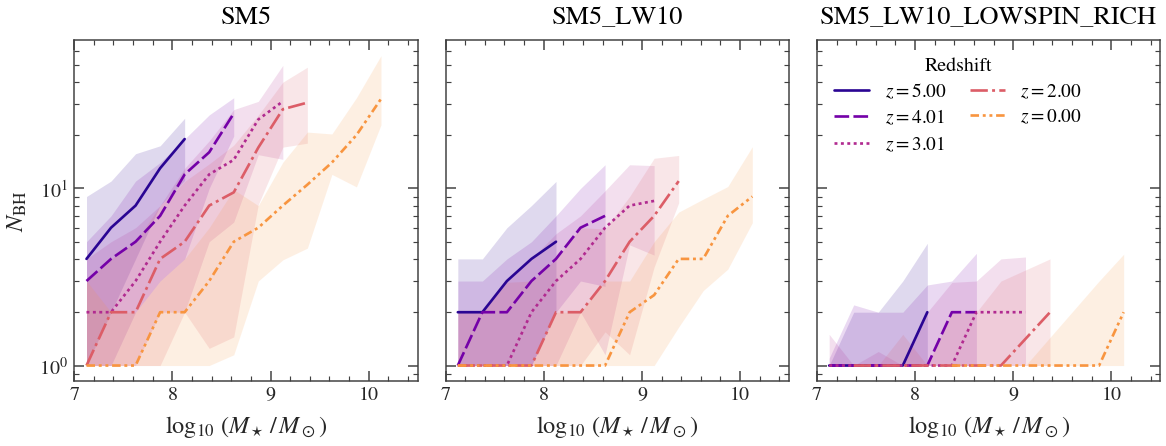

In [309]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4), sharex=True, sharey=True)
colors = ps.sequential_colors(len(REDSHIFTS), cmap='plasma', low=0.05, high=0.75)
linestyles = ps.line_styles(len(REDSHIFTS))

for ax, (sim_name, title) in zip(axes, SEED_MODELS.items()):
    hosts = load_hosts(sim_name)
    for target, color, linestyle in zip(REDSHIFTS, colors, linestyles):
        nearest = int(np.argmin(np.abs(hosts['redshifts'] - target)))
        this_snap = hosts['snap'] == hosts['snapshots'][nearest]
        particle_counts = brahma.groupcat.loadSubhalos_postprocessed(
            hosts['sim_file'], int(hosts['snapshots'][nearest]), fields='SubhaloLenType')[hosts['index'][this_snap]]
        resolved = ((particle_counts[:, 4] >= MIN_STAR_PARTICLES)
                    & (particle_counts[:, 1] >= MIN_DM_PARTICLES))
        centres, p5, p50, p95 = binned_percentiles(
            np.log10(hosts['stellar_mass'][this_snap][resolved]), hosts['bh_count'][this_snap][resolved])

        ax.fill_between(centres, p5, p95, color=color, alpha=0.15, lw=0)
        ax.plot(centres, p50, color=color, ls=linestyle,
                label=f"$z = {hosts['redshifts'][nearest]:.2f}$")
    ax.set_title(title)
    ax.set_yscale('log')
    ax.set_xlabel(r'$\log_{10}\,(M_\star\,/\,M_\odot)$')

axes[0].set_ylabel(r'$N_{\rm BH}$')
axes[0].set_xlim(7, 10.5)
axes[2].legend(title='Redshift', loc='upper left', ncols=2)
#fig.suptitle('Black-hole occupation versus host stellar mass')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'Nbh_vs_stellar_mass_seed_models.pdf')
plt.show()

## Black hole occupation fraction

Fraction of galaxies holding at least one BH (total), at least one BH inside the stellar half-mass radius (central), or at least one outside it (wandering), as a function of stellar mass. The catalogue only lists BH-hosting subhalos, so the denominator (every galaxy, with or without a BH) is read from the group catalogue and matched to the catalogue through `subhalo_index`. Galaxies need at least 50 star particles (about $1.1\times10^7\,M_\odot$) and at least 50 dark-matter particles (about $7.8\times10^7\,M_\odot$). The star-particle floor guarantees a resolved stellar half-mass radius, which the catalogue needs to classify a BH as central or wandering. The dark-matter floor removes satellites tidally stripped down to their stellar cores, which have usually lost their BHs.

**Kernel smoothing.** Give each galaxy $i$ a flag $o_i = 1$ if it is occupied and $0$ if not. At a stellar mass $m$ on the grid, galaxy $i$ (at $m_i$) gets a Gaussian weight

$$w_i(m) = \exp\!\left[-\frac{(m - m_i)^2}{2\sigma^2}\right],$$

which is 1 for a galaxy exactly at $m$ and falls toward 0 over a few $\sigma$. The occupation fraction is the weighted average of the flags,

$$f(m) = \frac{\sum_i w_i(m)\, o_i}{\sum_i w_i(m)}.$$

This is the same as binning galaxies and taking occupied / total, except that the bin has soft edges and moves smoothly with $m$. The kernel width is set by its FWHM, $\sigma = \mathrm{FWHM} / (2\sqrt{2\ln 2}) \approx \mathrm{FWHM}/2.355$, here 0.45 dex. The denominator $\sum_i w_i(m)$ is also roughly the number of galaxies within the kernel, so the curve is cut off where it drops below 8 and the box has too few galaxies to say anything.

In [310]:
PLOT_LOG_MSTAR = (5.0, 11.0)
MASS_GRID = np.linspace(*PLOT_LOG_MSTAR, 300)
KERNEL_FWHM_DEX = 0.6
KERNEL_SIGMA_DEX = KERNEL_FWHM_DEX / (2 * np.sqrt(2 * np.log(2)))
MIN_GALAXIES_IN_KERNEL = 8
GALAXIES_PER_BIN = 30


def load_galaxy_occupation(sim_name, redshift, min_lbol=0.0):
    """Stellar mass and total/central/wandering occupation flags of every resolved galaxy.

    Only BHs with a bolometric luminosity of at least `min_lbol` (erg/s) count as occupying a galaxy.
    """
    with h5py.File(DATA_DIR / f'wandering_bh_{sim_name}.hdf5', 'r') as f:
        snapshots, redshifts = f['snapshot/snap'][:], f['snapshot/redshift'][:]
        nearest = int(np.argmin(np.abs(redshifts - redshift)))
        in_snap = f['bh/snap'][:] == snapshots[nearest]
        host_index = f['bh/subhalo_index'][:][in_snap]
        is_wandering = f['bh/is_wandering'][:][in_snap]
        bright = f['bh/lbol_erg_s'][:][in_snap] >= min_lbol
        host_index, is_wandering = host_index[bright], is_wandering[bright]
        sim_file = f.attrs['sim_path'] + f.attrs['sim_name']
        h = f.attrs['HubbleParam']

    subhalos = brahma.groupcat.loadSubhalos_postprocessed(
        sim_file, int(snapshots[nearest]), fields=['SubhaloLenType', 'SubhaloMassType'])
    stellar_mass = subhalos['SubhaloMassType'][:, 4] * 1e10 / h
    galaxies = np.flatnonzero((subhalos['SubhaloLenType'][:, 4] >= MIN_STAR_PARTICLES)
                              & (subhalos['SubhaloLenType'][:, 1] >= MIN_DM_PARTICLES))
    return dict(redshift=float(redshifts[nearest]),
                log_mstar=np.log10(stellar_mass[galaxies]),
                total=np.isin(galaxies, host_index),
                central=np.isin(galaxies, host_index[~is_wandering]),
                wandering=np.isin(galaxies, host_index[is_wandering]))


def bhof(log_mstar, occupied, mass_grid=MASS_GRID, sigma=KERNEL_SIGMA_DEX,
         min_galaxies=MIN_GALAXIES_IN_KERNEL):
    """Occupied fraction at each point of `mass_grid`: a Gaussian-weighted average of the 0/1 flags."""
    weights = np.exp(-0.5 * ((log_mstar[:, None] - mass_grid[None, :]) / sigma) ** 2)
    n_in_kernel = weights.sum(axis=0)
    fraction = (weights * occupied[:, None]).sum(axis=0) / n_in_kernel
    return mass_grid, np.where(n_in_kernel >= min_galaxies, fraction, np.nan)


def bhof_adaptive(log_mstar, occupied, galaxies_per_bin=GALAXIES_PER_BIN):
    """Occupied fraction in equal-count stellar-mass bins, plotted at each bin's mean mass."""
    order = np.argsort(log_mstar)
    bins = np.array_split(order, max(len(order) // galaxies_per_bin, 1))
    return (np.array([log_mstar[b].mean() for b in bins]),
            np.array([occupied[b].mean() for b in bins]))


# Same fixed bins as the earlier Paper6 BHOF figures: 15 bin centres from 3 to 11 (0.571 dex wide)
BIN_CENTRES = np.linspace(3, 11, 15)
BIN_WIDTH = np.diff(BIN_CENTRES)[0]
MIN_GALAXIES_PER_BIN = 10


def bhof_binned(log_mstar, occupied, centres=BIN_CENTRES, width=BIN_WIDTH, min_galaxies=MIN_GALAXIES_PER_BIN):
    """Occupied fraction in fixed-width bins, plotted at the bin centres.

    Bins holding fewer than `min_galaxies` galaxies are dropped.
    """
    in_bin = np.abs(log_mstar[:, None] - centres[None, :]) < width / 2
    n_galaxies = in_bin.sum(axis=0)
    n_occupied = (in_bin & occupied[:, None]).sum(axis=0)
    keep = n_galaxies >= min_galaxies
    return centres[keep], n_occupied[keep] / n_galaxies[keep]


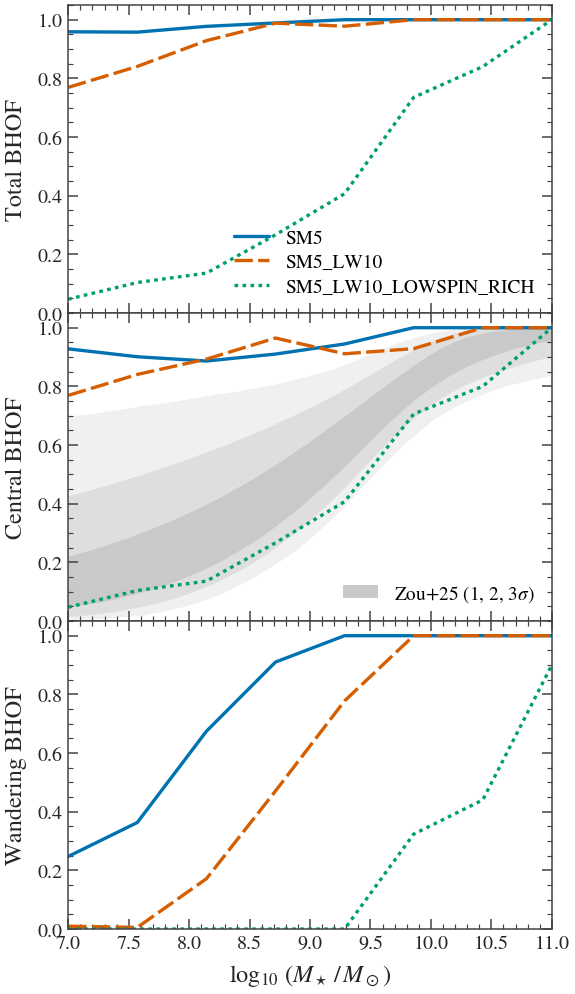

In [311]:
BHOF_REDSHIFT = 0
BHOF_METHOD = 'bins'   # 'bins' (fixed 0.57 dex), 'kde' (Gaussian kernel) or 'adaptive' (equal-count bins)
bhof_curve = {'bins': bhof_binned, 'kde': bhof, 'adaptive': bhof_adaptive}[BHOF_METHOD]
panels = [('total', 'Total BHOF'), ('central', 'Central BHOF'), ('wandering', 'Wandering BHOF')]

fig, axes = plt.subplots(3, 1, figsize=(5.2, 10), sharex=True)
# Okabe-Ito blue, vermillion, bluish green: orange washes out against white and the grey band
colors = [ps.OKABE_ITO[i] for i in (0, 4, 2)]
linestyles = ps.line_styles(len(SEED_MODELS))

for (sim_name, label), color, linestyle in zip(SEED_MODELS.items(), colors, linestyles):
    galaxies = load_galaxy_occupation(sim_name, BHOF_REDSHIFT)
    for ax, (key, _) in zip(axes, panels):
        ax.plot(*bhof_curve(galaxies['log_mstar'], galaxies[key]), color=color, ls=linestyle, lw=2, label=label)

# Zou+25 X-ray constraint on nuclear (central) MBHs: 1, 2 and 3 sigma posterior ranges
# Table 2 machine-readable file (ApJ 992, 176): log M*, then 3/2/1 sigma lower, median, 1/2/3 sigma upper
zou = np.loadtxt('../../Data/zou25_table2_mrt.txt', skiprows=20)
for lower, upper, shade in [(1, 7, '0.94'), (2, 6, '0.87'), (3, 5, '0.79')]:
    axes[1].fill_between(zou[:, 0], zou[:, lower], zou[:, upper], color=shade, lw=0, zorder=0)
zou_handle = axes[1].fill_between([], [], color='0.79', label=r'Zou+25 (1, 2, 3$\sigma$)')
axes[1].legend(handles=[zou_handle], loc='lower right', frameon=False)

for ax, (_, panel_label) in zip(axes, panels):
    ax.set_ylabel(panel_label)
    ax.set_ylim(0, 1.05)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_xlim(7,11)
#axes[-1].set_xlim(*PLOT_LOG_MSTAR)
axes[-1].set_xlabel(r'$\log_{10}\,(M_\star\,/\,M_\odot)$')
axes[0].legend(loc='lower right', frameon=False)
fig.subplots_adjust(hspace=0)
fig.savefig(FIGURE_DIR / f'bhof_seed_models_z{BHOF_REDSHIFT}_{BHOF_METHOD}.pdf', bbox_inches='tight')
plt.show()

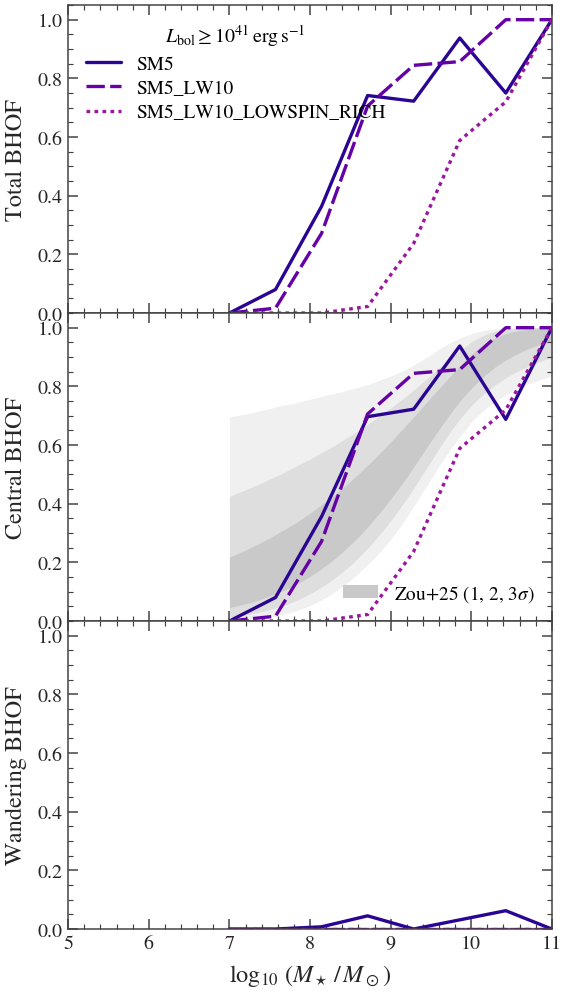

In [315]:
MIN_LBOL = 1e41   # erg/s; only BHs at least this luminous count as occupying a galaxy

fig, axes = plt.subplots(3, 1, figsize=(5.2, 10), sharex=True)

for (sim_name, label), color, linestyle in zip(SEED_MODELS.items(), colors, linestyles):
    galaxies = load_galaxy_occupation(sim_name, BHOF_REDSHIFT, min_lbol=MIN_LBOL)
    for ax, (key, _) in zip(axes, panels):
        ax.plot(*bhof_curve(galaxies['log_mstar'], galaxies[key]), color=color, ls=linestyle, lw=2, label=label)

for ax, (_, panel_label) in zip(axes, panels):
    ax.set_ylabel(panel_label)
    ax.set_ylim(0, 1.05)
    ax.set_yticks(np.arange(0, 1.01, 0.2))


zou = np.loadtxt('../../Data/zou25_table2_mrt.txt', skiprows=20)
for lower, upper, shade in [(1, 7, '0.94'), (2, 6, '0.87'), (3, 5, '0.79')]:
    axes[1].fill_between(zou[:, 0], zou[:, lower], zou[:, upper], color=shade, lw=0, zorder=0)
zou_handle = axes[1].fill_between([], [], color='0.79', label=r'Zou+25 (1, 2, 3$\sigma$)')
axes[1].legend(handles=[zou_handle], loc='lower right', frameon=False)

axes[-1].set_xlim(*PLOT_LOG_MSTAR)
axes[-1].set_xlabel(r'$\log_{10}\,(M_\star\,/\,M_\odot)$')
axes[0].legend(loc='upper left', frameon=False,
               title=rf'$L_{{\rm bol}} \geq 10^{{{np.log10(MIN_LBOL):g}}}\,{{\rm erg\,s^{{-1}}}}$')
fig.subplots_adjust(hspace=0)
fig.savefig(FIGURE_DIR / f'bhof_seed_models_z{BHOF_REDSHIFT}_{BHOF_METHOD}_lbol{np.log10(MIN_LBOL):g}.pdf', bbox_inches='tight')
plt.show()

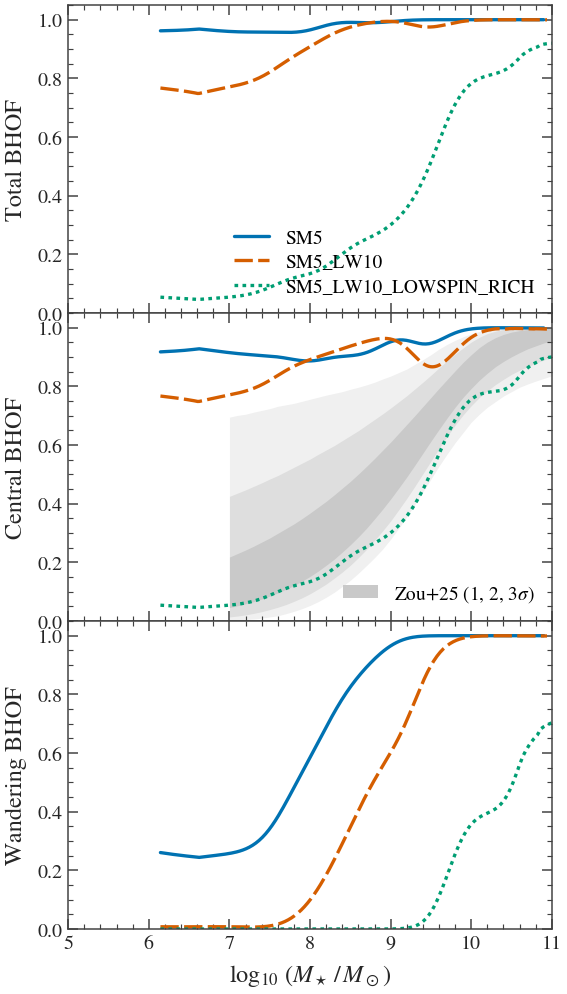

In [313]:
NEIGHBOURS = 40         # galaxies the kernel is stretched to reach
MAX_SIGMA_DEX = 0.5     # blank points that would need a wider kernel than this


def bhof_adaptive_kernel(log_mstar, occupied, mass_grid=MASS_GRID, neighbours=NEIGHBOURS,
                         min_sigma=KERNEL_SIGMA_DEX, max_sigma=MAX_SIGMA_DEX):
    """Gaussian-weighted occupied fraction whose width follows the local galaxy density.

    At each grid point sigma is half the distance to the `neighbours`-th nearest galaxy
    in log stellar mass, so the kernel is wide where galaxies are sparse and narrow where
    they are plentiful. It is never narrower than `min_sigma`, and points that would need
    more than `max_sigma` are returned as NaN.
    """
    distance = np.abs(log_mstar[:, None] - mass_grid[None, :])
    sigma = np.maximum(np.partition(distance, neighbours - 1, axis=0)[neighbours - 1] / 2, min_sigma)
    weights = np.exp(-0.5 * (distance / sigma) ** 2)
    fraction = (weights * occupied[:, None]).sum(axis=0) / weights.sum(axis=0)
    return mass_grid, np.where(sigma <= max_sigma, fraction, np.nan)


fig, axes = plt.subplots(3, 1, figsize=(5.2, 10), sharex=True)

for (sim_name, label), color, linestyle in zip(SEED_MODELS.items(), colors, linestyles):
    galaxies = load_galaxy_occupation(sim_name, BHOF_REDSHIFT)
    for ax, (key, _) in zip(axes, panels):
        ax.plot(*bhof_adaptive_kernel(galaxies['log_mstar'], galaxies[key]),
                color=color, ls=linestyle, lw=2, label=label)

for lower, upper, shade in [(1, 7, '0.94'), (2, 6, '0.87'), (3, 5, '0.79')]:
    axes[1].fill_between(zou[:, 0], zou[:, lower], zou[:, upper], color=shade, lw=0, zorder=0)
zou_handle = axes[1].fill_between([], [], color='0.79', label=r'Zou+25 (1, 2, 3$\sigma$)')
axes[1].legend(handles=[zou_handle], loc='lower right', frameon=False)

for ax, (_, panel_label) in zip(axes, panels):
    ax.set_ylabel(panel_label)
    ax.set_ylim(0, 1.05)
    ax.set_yticks(np.arange(0, 1.01, 0.2))

axes[-1].set_xlim(*PLOT_LOG_MSTAR)
axes[-1].set_xlabel(r'$\log_{10}\,(M_\star\,/\,M_\odot)$')
axes[0].legend(loc='lower right', frameon=False)
fig.subplots_adjust(hspace=0)
fig.savefig(FIGURE_DIR / f'bhof_seed_models_z{BHOF_REDSHIFT}_adaptive_kernel.pdf', bbox_inches='tight')
plt.show()

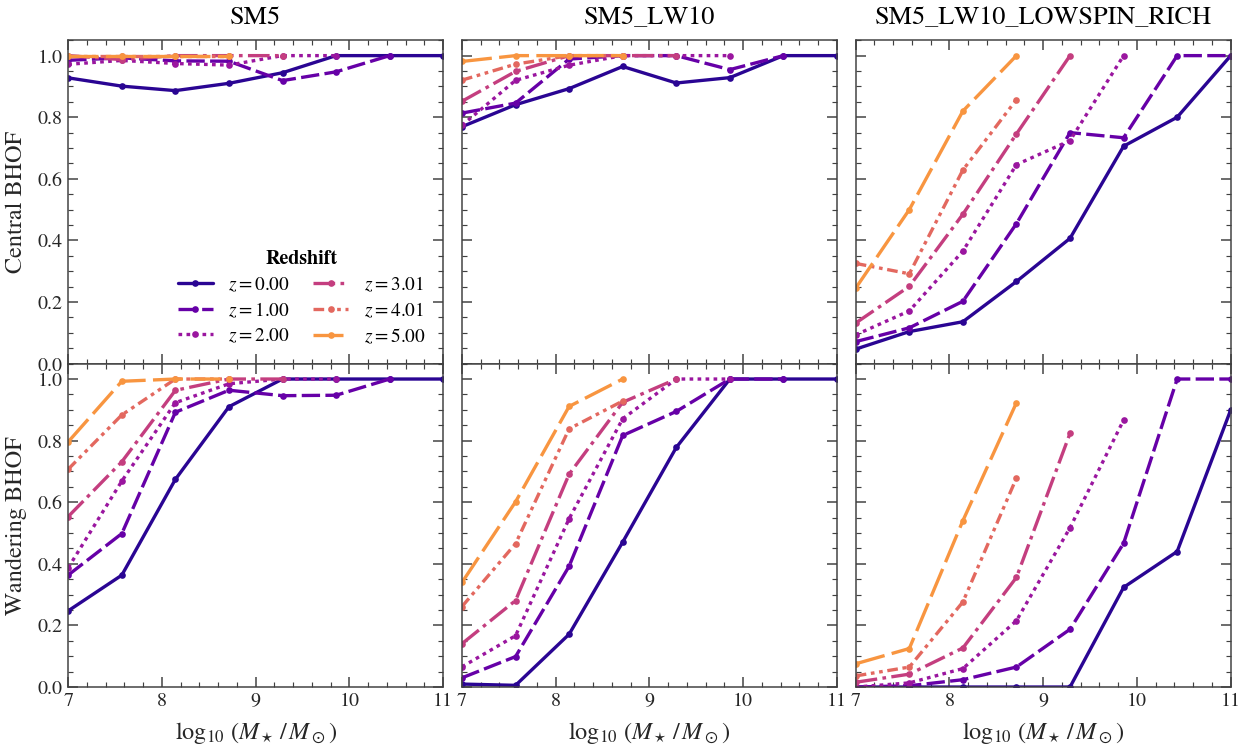

In [314]:
REDSHIFT_EVOLUTION = [0, 1, 2, 3, 4, 5]   # the LOWSPIN_RICH catalogue has no snapshots above z = 5
rows = [('central', 'Central BHOF'), ('wandering', 'Wandering BHOF')]
colors = ps.sequential_colors(len(REDSHIFT_EVOLUTION), cmap='plasma', low=0.05, high=0.75)
linestyles = ps.line_styles(len(REDSHIFT_EVOLUTION))

fig, axes = plt.subplots(2, 3, figsize=(12.5, 7), sharex=True, sharey=True)

for column, (sim_name, title) in enumerate(SEED_MODELS.items()):
    for redshift, color, linestyle in zip(REDSHIFT_EVOLUTION, colors, linestyles):
        galaxies = load_galaxy_occupation(sim_name, redshift)
        for row, (key, _) in enumerate(rows):
            axes[row, column].plot(*bhof_curve(galaxies['log_mstar'], galaxies[key]), color=color, ls=linestyle,
                                   lw=2, marker='o', ms=3, label=rf"$z = {galaxies['redshift']:.2f}$")
    axes[0, column].set_title(title)
    axes[-1, column].set_xlabel(r'$\log_{10}\,(M_\star\,/\,M_\odot)$')

for row, (_, row_label) in enumerate(rows):
    axes[row, 0].set_ylabel(row_label)

axes[0, 0].set_xlim(7, 11)
axes[0, 0].set_ylim(0, 1.05)
axes[0, 0].set_yticks(np.arange(0, 1.01, 0.2))
axes[0, 0].legend(loc='lower right', ncols=2, frameon=False, title='Redshift',
                  title_fontproperties={'weight': 'semibold'})
fig.subplots_adjust(hspace=0, wspace=0.05)
fig.savefig(FIGURE_DIR / f'bhof_central_wandering_vs_redshift_{BHOF_METHOD}.pdf', bbox_inches='tight')
plt.show()

In [ ]:
## Central BHOF at z = 0: BRAHMA seed models against Zou+25 and earlier simulations
# Literature curves digitized from a published z = 0 BHOF comparison figure (see the file header)
literature = np.genfromtxt('../../Data/bhof_literature_z0_digitized.txt', names=True)
PREVIOUS_SIMULATIONS = {'EAGLE': '#025B59', 'SIMBA': '#96F97A', 'Horizon_AGN': '#05C2AC',
                        'Illustris': '#0063FC', 'TNG100': '#990BEB', 'TNG300': '#C59EEF'}
DIGITIZED_CENTRAL = {'ASTRID-full': ('#BE0019', 'ASTRID full'),
                     'ASTRID-heavy': ('#FF796D', 'ASTRID heavy')}
# Okabe-Ito blue, vermillion, black: bluish green would blend with the Horizon-AGN and EAGLE teals
seed_colors = [ps.OKABE_ITO[i] for i in (0, 4, 7)]
seed_linestyles = ps.line_styles(len(SEED_MODELS))

fig, ax = plt.subplots(figsize=(7, 5))

for lower, upper, shade in [(1, 7, '0.94'), (2, 6, '0.87'), (3, 5, '0.79')]:
    ax.fill_between(zou[:, 0], zou[:, lower], zou[:, upper], color=shade, lw=0, zorder=0)
ax.plot(zou[:, 0], zou[:, 4], color='0.5', lw=1, zorder=0)
zou_handle = ax.fill_between([], [], color='0.79', label=r'Zou+25 (1, 2, 3$\sigma$)')

previous_handles = [ax.plot(literature['log_mstar'], literature[name], color=color, lw=1.2,
                            label=name.replace('_', '-'))[0]
                    for name, color in PREVIOUS_SIMULATIONS.items()]
digitized_handles = [ax.plot(literature['log_mstar'], literature[f"{name.replace('-', '_')}_central"], color=color, lw=2.5, ls='--',
                             label=label)[0]
                     for name, (color, label) in DIGITIZED_CENTRAL.items()]

brahma_handles = []
for (sim_name, label), color, linestyle in zip(SEED_MODELS.items(), seed_colors, seed_linestyles):
    galaxies = load_galaxy_occupation(sim_name, BHOF_REDSHIFT)
    brahma_handles += ax.plot(*bhof_curve(galaxies['log_mstar'], galaxies['central']),
                              color=color, ls=linestyle, lw=2.5, marker='o', ms=4, label=label)

legend_kwargs = dict(frameon=False, fontsize='small', title_fontproperties={'weight': 'semibold'})
ax.add_artist(ax.legend(handles=brahma_handles, title='BRAHMA', loc='upper left',
                        bbox_to_anchor=(0, 0.83), **legend_kwargs))
ax.add_artist(ax.legend(handles=previous_handles + [zou_handle], title='Previous work',
                        loc='lower right', **legend_kwargs))
ax.legend(handles=digitized_handles, title='Digitized comparison', loc='center right', **legend_kwargs)

ax.set_xlim(7, 12)
ax.set_ylim(0, 1.02)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_xlabel(r'$\log_{10}\,(M_\star\,/\,M_\odot)$')
ax.set_ylabel('Central BHOF')
ax.text(0.97, 0.97, rf'$z = {BHOF_REDSHIFT}$', transform=ax.transAxes, ha='right', va='top')
fig.savefig(FIGURE_DIR / f'bhof_central_literature_z{BHOF_REDSHIFT}_{BHOF_METHOD}.pdf', bbox_inches='tight')
plt.show()